In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.linear_model import SGDRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

In [37]:
df = pd.read_csv("customer_data.csv")
df.head() # preview data


,id,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,1,27,Male,40682,Bachelor,East,Gold,frequent,18249,Books,0,6
1,2,29,Male,15317,Masters,West,Regular,rare,4557,Clothing,1,6
2,3,37,Male,38849,Bachelor,West,Silver,rare,11822,Clothing,0,6
3,4,30,Male,11568,HighSchool,South,Regular,frequent,4098,Food,0,7
4,5,31,Female,46952,College,North,Regular,occasional,19685,Clothing,1,5


In [38]:
df.shape

(100000, 12)

There are 100000 rows and 12 columns


In [39]:
df.duplicated().sum()

0

In [40]:
df.isna().sum()

id                    0
age                   0
gender                0
income                0
education             0
region                0
loyalty_status        0
purchase_frequency    0
purchase_amount       0
product_category      0
promotion_usage       0
satisfaction_score    0
dtype: int64

There aren't any duplicated rows or missing values


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   id                  100000 non-null  int64 
 1   age                 100000 non-null  int64 
 2   gender              100000 non-null  object
 3   income              100000 non-null  int64 
 4   education           100000 non-null  object
 5   region              100000 non-null  object
 6   loyalty_status      100000 non-null  object
 7   purchase_frequency  100000 non-null  object
 8   purchase_amount     100000 non-null  int64 
 9   product_category    100000 non-null  object
 10  promotion_usage     100000 non-null  int64 
 11  satisfaction_score  100000 non-null  int64 
dtypes: int64(6), object(6)
memory usage: 9.2+ MB


In [42]:
# drop unnecessary column
df = df.drop(columns=['id'])

In [43]:
df.head()

,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,27,Male,40682,Bachelor,East,Gold,frequent,18249,Books,0,6
1,29,Male,15317,Masters,West,Regular,rare,4557,Clothing,1,6
2,37,Male,38849,Bachelor,West,Silver,rare,11822,Clothing,0,6
3,30,Male,11568,HighSchool,South,Regular,frequent,4098,Food,0,7
4,31,Female,46952,College,North,Regular,occasional,19685,Clothing,1,5


In [44]:
numerical_cols = df.select_dtypes(include=np.number).columns

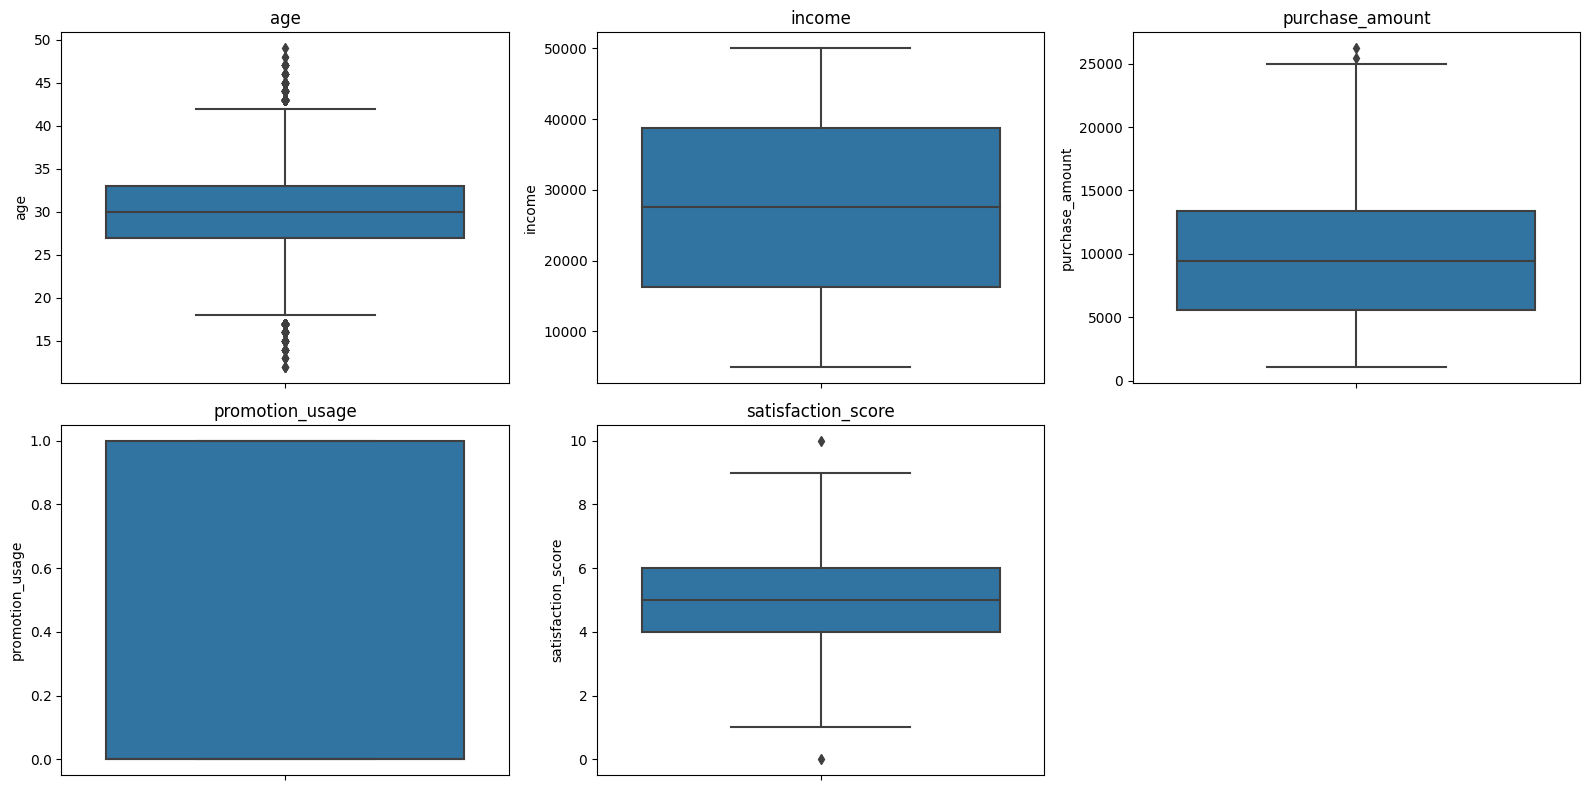

In [45]:
# analyze boxplot for numerical columns
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

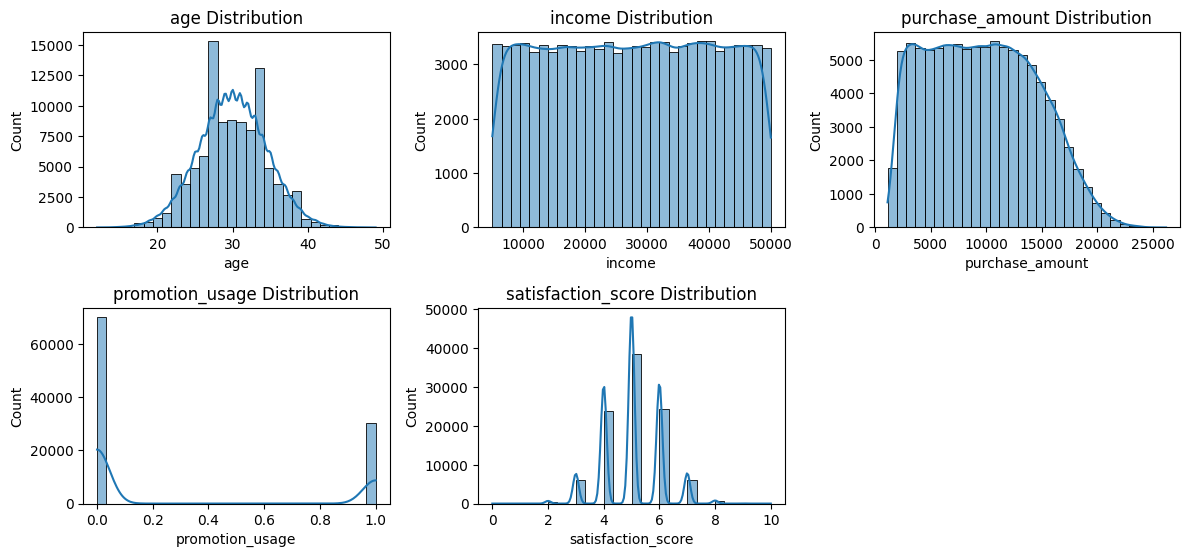

In [46]:
# data distribution
plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"{col} Distribution")

plt.tight_layout()
plt.show()

In [47]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

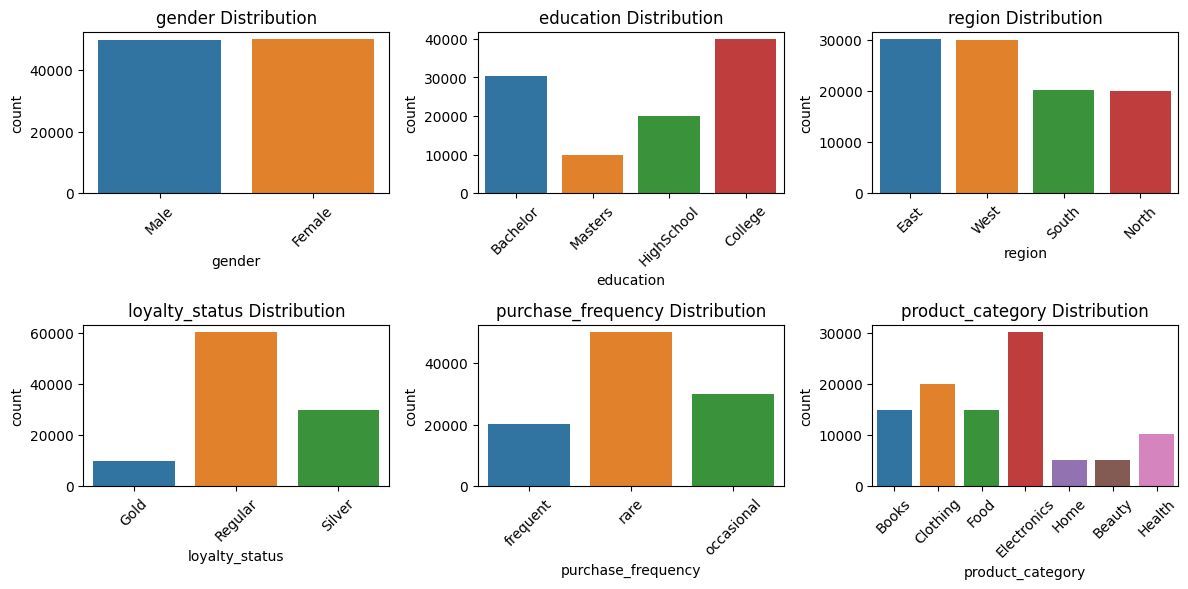

In [48]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 3, i)
    sns.countplot(data=df, x=col)
    plt.title(f"{col} Distribution")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

<Axes: >

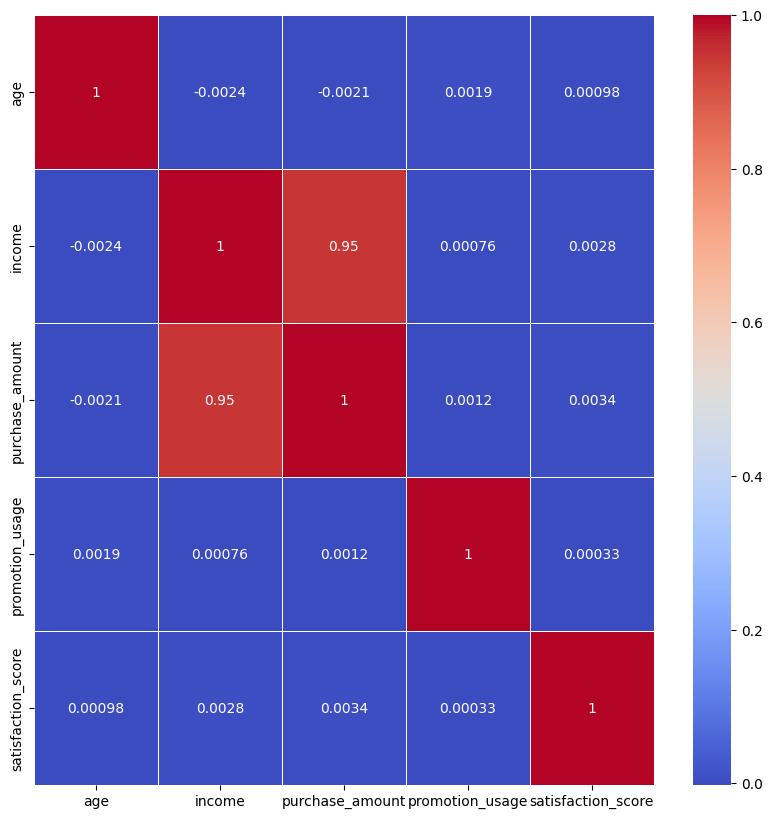

In [49]:
corr = df[numerical_cols].corr()
plt.figure(figsize=(10,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)

In [50]:
df.describe()

,age,income,purchase_amount,promotion_usage,satisfaction_score
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,30.003260,27516.269880,9634.790840,0.300800,5.009650
std,4.480535,12996.782587,4799.339449,0.458608,1.038714
min,12.000000,5000.000000,1118.000000,0.000000,0.000000
25%,27.000000,16271.750000,5583.000000,0.000000,4.000000
50%,30.000000,27584.500000,9452.000000,0.000000,5.000000
75%,33.000000,38747.250000,13350.000000,1.000000,6.000000
max,49.000000,50000.000000,26204.000000,1.000000,10.000000


In [51]:
for col in df.columns:
    print(col, df[col].unique())

age [27 29 37 30 31 38 32 24 28 35 21 33 25 22 34 36 40 23 39 20 26 44 19 41
 18 17 42 43 45 16 15 47 13 14 48 46 49 12]
gender ['Male' 'Female']
income [40682 15317 38849 ... 27092 28552 35207]
education ['Bachelor' 'Masters' 'HighSchool' 'College']
region ['East' 'West' 'South' 'North']
loyalty_status ['Gold' 'Regular' 'Silver']
purchase_frequency ['frequent' 'rare' 'occasional']
purchase_amount [18249  4557 11822 ... 23851 20808 18104]
product_category ['Books' 'Clothing' 'Food' 'Electronics' 'Home' 'Beauty' 'Health']
promotion_usage [0 1]
satisfaction_score [ 6  7  5  3  4  2  8  9  1 10  0]


In [52]:
# renaming the values to make it tidier to read
df['purchase_frequency'] = df['purchase_frequency'].str.title()
df['education'] = df['education'].str.replace('HighSchool', 'Highschool', regex=False)

In [53]:
df.head()

,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
0,27,Male,40682,Bachelor,East,Gold,Frequent,18249,Books,0,6
1,29,Male,15317,Masters,West,Regular,Rare,4557,Clothing,1,6
2,37,Male,38849,Bachelor,West,Silver,Rare,11822,Clothing,0,6
3,30,Male,11568,Highschool,South,Regular,Frequent,4098,Food,0,7
4,31,Female,46952,College,North,Regular,Occasional,19685,Clothing,1,5


Remove the outliers before modelling

In [54]:
iqr = df[numerical_cols].quantile(0.75) - df[numerical_cols].quantile(0.25)
lower_bound = df[numerical_cols].quantile(0.25) - 1.5 * iqr
upper_bound = df[numerical_cols].quantile(0.75) + 1.5 * iqr

for col in numerical_cols:
    df = df[(df[col] >= lower_bound[col]) & (df[col] <= upper_bound[col])]  
    

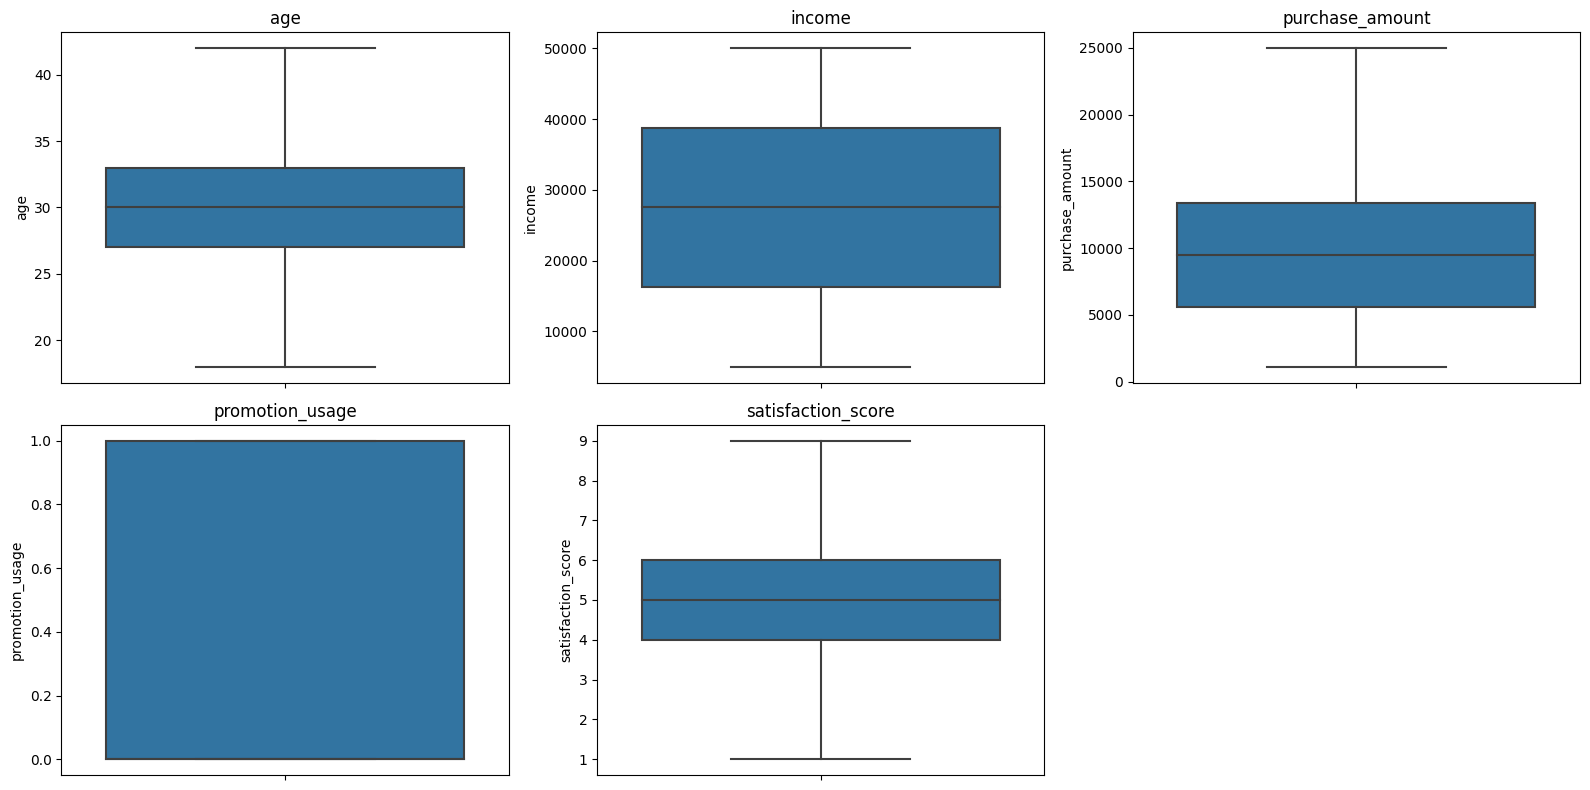

In [55]:
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

In [56]:
df.describe()

,age,income,purchase_amount,promotion_usage,satisfaction_score
count,99483.000000,99483.000000,99483.000000,99483.000000,99483.000000
mean,30.006081,27513.711378,9633.967009,0.300855,5.009791
std,4.379638,12995.406160,4798.451842,0.458632,1.038688
min,18.000000,5000.000000,1118.000000,0.000000,1.000000
25%,27.000000,16271.000000,5583.500000,0.000000,4.000000
50%,30.000000,27584.000000,9452.000000,0.000000,5.000000
75%,33.000000,38743.000000,13348.500000,1.000000,6.000000
max,42.000000,50000.000000,24967.000000,1.000000,9.000000


# Modelling

In [57]:
# All imports already loaded in Cell 1

### Turn categorical values to numerical values

In [58]:
le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 99483 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   age                 99483 non-null  int64
 1   gender              99483 non-null  int32
 2   income              99483 non-null  int64
 3   education           99483 non-null  int32
 4   region              99483 non-null  int32
 5   loyalty_status      99483 non-null  int32
 6   purchase_frequency  99483 non-null  int32
 7   purchase_amount     99483 non-null  int64
 8   product_category    99483 non-null  int32
 9   promotion_usage     99483 non-null  int64
 10  satisfaction_score  99483 non-null  int64
dtypes: int32(6), int64(5)
memory usage: 6.8 MB


In [60]:
X = df.drop(columns=['income'])
y = df['income']

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [62]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [63]:
# mean_absolute_percentage_error already imported in Cell 1


 Linear Regression
Epochs/Iterasi : N/A (Closed-form)
Akurasi        : 86.94%
MAE            : 3097.53
RMSE           : 4119.05
R² Score       : 0.8988


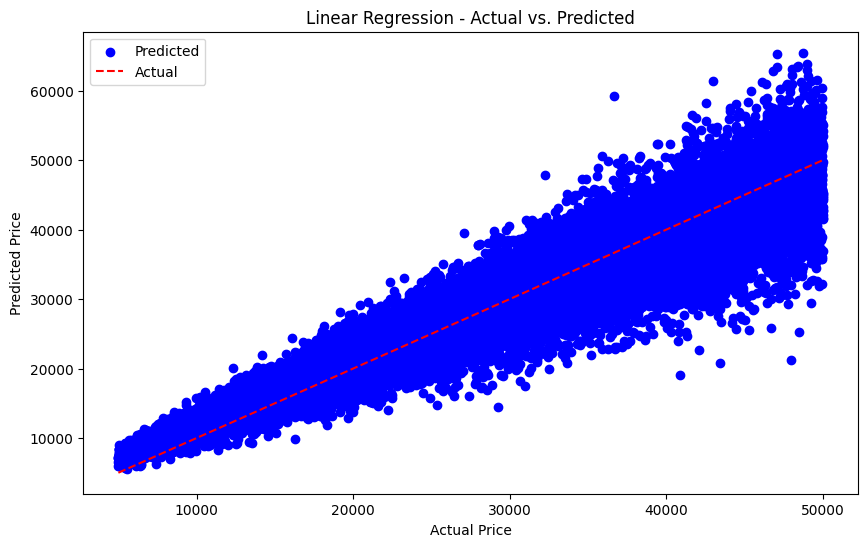


 Random Forest
Epochs/Iterasi : N/A (Closed-form)
Akurasi        : 88.64%
MAE            : 2873.23
RMSE           : 3843.92
R² Score       : 0.9119


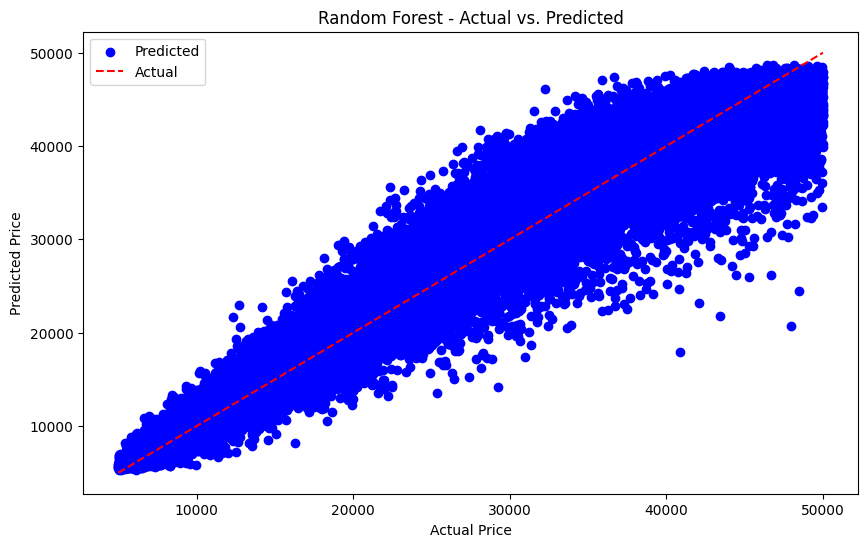


 SGD Regressor
Epochs/Iterasi : 407
Akurasi        : -76411674979585.44%
MAE            : 20922802949596116.00
RMSE           : 23382890276352000.00
R² Score       : -3260043347337027352788992.0000


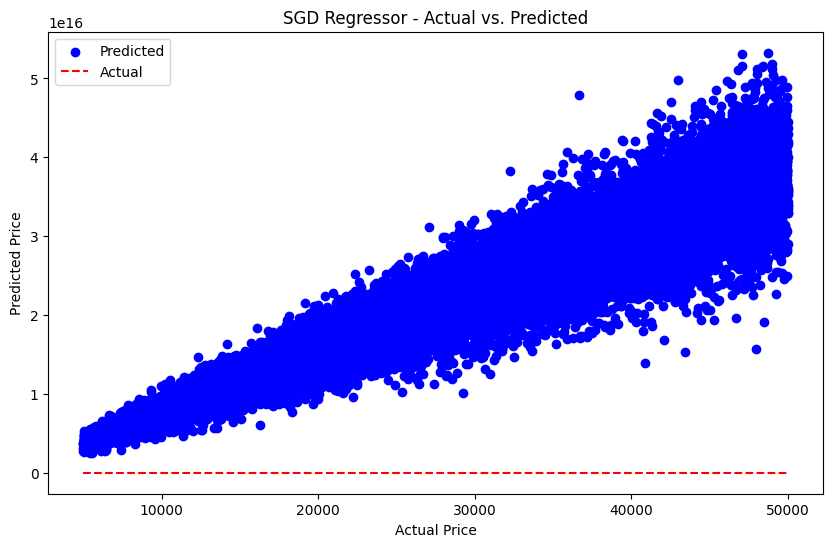


 TABEL PERBANDINGAN MODEL
               Model             Epochs  Accuracy (%)           MAE           MSE          RMSE            R2
0  Linear Regression  N/A (Closed-form)  8.694000e+01  3.097530e+03  1.696655e+07  4.119050e+03  8.988000e-01
1      Random Forest  N/A (Closed-form)  8.864000e+01  2.873230e+03  1.477572e+07  3.843920e+03  9.119000e-01
2      SGD Regressor                407 -7.641167e+13  2.092280e+16  5.467596e+32  2.338289e+16 -3.260043e+24


In [64]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'SGD Regressor': SGDRegressor(max_iter=1000, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    
    # Epoch / iterasi
    iters = getattr(model, 'n_iter_', 'N/A (Closed-form)')
    print(f'\n {name}')
    print(f'Epochs/Iterasi : {iters}')
    
    y_pred = model.predict(X_test)
    
    mse  = mean_squared_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    accuracy_pct = 100 - (mape * 100)
    
    print(f'Akurasi        : {accuracy_pct:.2f}%')
    print(f'MAE            : {mae:.2f}')
    print(f'RMSE           : {rmse:.2f}')
    print(f'R² Score       : {r2:.4f}')
    
    results.append({
        'Model': name,
        'Epochs': iters,
        'Accuracy (%)': round(accuracy_pct, 2),
        'MAE': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'R2': round(r2, 4)
    })
    
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, color='blue', label='Predicted')
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)],
             color='red', linestyle='--', label='Actual')
    plt.title(f'{name} - Actual vs. Predicted')
    plt.xlabel('Actual Price')
    plt.ylabel('Predicted Price')
    plt.legend()
    plt.show()

results_df = pd.DataFrame(results)
print('\n TABEL PERBANDINGAN MODEL')
print(results_df.to_string())

## Hyperparameter Tuning

In [65]:
# Hyperparameter Tuning - Random Forest

param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_base = RandomForestRegressor(random_state=42)
grid_search_rf = GridSearchCV(rf_base, param_grid_rf, cv=3,
                               scoring='r2', n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train, y_train)

print(f'\nParameter Terbaik RF : {grid_search_rf.best_params_}')
print(f'R² Score Terbaik RF  : {grid_search_rf.best_score_:.4f}')

# Hyperparameter Tuning - SGD Regressor

param_grid_sgd = {
    'max_iter': [500, 1000, 2000],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['constant', 'optimal', 'adaptive']
}

sgd_base = SGDRegressor(random_state=42)
grid_search_sgd = GridSearchCV(sgd_base, param_grid_sgd, cv=3,
                                scoring='r2', n_jobs=-1, verbose=1)
grid_search_sgd.fit(X_train_scaled, y_train)

print(f'\nParameter Terbaik SGD : {grid_search_sgd.best_params_}')
print(f'R² Score Terbaik SGD  : {grid_search_sgd.best_score_:.4f}')

Fitting 3 folds for each of 18 candidates, totalling 54 fits

Parameter Terbaik RF : {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
R² Score Terbaik RF  : 0.9182
Fitting 3 folds for each of 27 candidates, totalling 81 fits

Parameter Terbaik SGD : {'alpha': 0.0001, 'learning_rate': 'adaptive', 'max_iter': 500}
R² Score Terbaik SGD  : 0.8998


### Evaluasi Model Setelah Hyperparameter Tuning

In [66]:
print('HASIL SETELAH HYPERPARAMETER TUNING \n')

# Random Forest terbaik
best_rf = grid_search_rf.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)
mape_rf  = mean_absolute_percentage_error(y_test, y_pred_rf_tuned)
acc_rf   = 100 - (mape_rf * 100)
r2_rf    = r2_score(y_test, y_pred_rf_tuned)
rmse_rf  = root_mean_squared_error(y_test, y_pred_rf_tuned)
mae_rf   = mean_absolute_error(y_test, y_pred_rf_tuned)
print(f'Random Forest (Tuned)')
print(f'  Akurasi   : {acc_rf:.2f}%')
print(f'  R² Score  : {r2_rf:.4f}')
print(f'  MAE       : {mae_rf:.2f}')
print(f'  RMSE      : {rmse_rf:.2f}')
print(f'  Parameter : {grid_search_rf.best_params_}')

# SGD terbaik
best_sgd = grid_search_sgd.best_estimator_
y_pred_sgd_tuned = best_sgd.predict(X_test_scaled)
mape_sgd  = mean_absolute_percentage_error(y_test, y_pred_sgd_tuned)
acc_sgd   = 100 - (mape_sgd * 100)
r2_sgd    = r2_score(y_test, y_pred_sgd_tuned)
rmse_sgd  = root_mean_squared_error(y_test, y_pred_sgd_tuned)
mae_sgd   = mean_absolute_error(y_test, y_pred_sgd_tuned)
print(f'\nSGD Regressor (Tuned)')
print(f'  Akurasi   : {acc_sgd:.2f}%')
print(f'  R² Score  : {r2_sgd:.4f}')
print(f'  MAE       : {mae_sgd:.2f}')
print(f'  RMSE      : {rmse_sgd:.2f}')
print(f'  Epoch     : {grid_search_sgd.best_params_["max_iter"]}')
print(f'  Parameter : {grid_search_sgd.best_params_}')

# Tabel perbandingan sebelum vs sesudah tuning
print('\n PERBANDINGAN SEBELUM vs SESUDAH TUNING')
comparison = pd.DataFrame([
    {'Model': 'Random Forest (Before)', 'Accuracy (%)': results_df[results_df['Model']=='Random Forest']['Accuracy (%)'].values[0], 'R2': results_df[results_df['Model']=='Random Forest']['R2'].values[0]},
    {'Model': 'Random Forest (Tuned)',  'Accuracy (%)': round(acc_rf, 2),  'R2': round(r2_rf, 4)},
    {'Model': 'SGD Regressor (Before)', 'Accuracy (%)': results_df[results_df['Model']=='SGD Regressor']['Accuracy (%)'].values[0], 'R2': results_df[results_df['Model']=='SGD Regressor']['R2'].values[0]},
    {'Model': 'SGD Regressor (Tuned)',  'Accuracy (%)': round(acc_sgd, 2), 'R2': round(r2_sgd, 4)},
])
print(comparison.to_string())

HASIL SETELAH HYPERPARAMETER TUNING 

Random Forest (Tuned)
  Akurasi   : 89.13%
  R² Score  : 0.9176
  MAE       : 2772.27
  RMSE      : 3717.20
  Parameter : {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}

SGD Regressor (Tuned)
  Akurasi   : 86.93%
  R² Score  : 0.8988
  MAE       : 3097.68
  RMSE      : 4119.04
  Epoch     : 500
  Parameter : {'alpha': 0.0001, 'learning_rate': 'adaptive', 'max_iter': 500}

 PERBANDINGAN SEBELUM vs SESUDAH TUNING
                    Model  Accuracy (%)            R2
0  Random Forest (Before)  8.864000e+01  9.119000e-01
1   Random Forest (Tuned)  8.913000e+01  9.176000e-01
2  SGD Regressor (Before) -7.641167e+13 -3.260043e+24
3   SGD Regressor (Tuned)  8.693000e+01  8.988000e-01


### Test relative error for 5 targets.

In [67]:
samples = df.sample(5, random_state=42)
samples.head()

,age,gender,income,education,region,loyalty_status,purchase_frequency,purchase_amount,product_category,promotion_usage,satisfaction_score
88620,28,1,26245,1,3,1,2,8570,3,0,6
39599,38,1,36974,3,0,2,2,14458,0,0,5
18740,31,0,9353,2,0,1,2,3234,3,1,5
1726,24,1,15460,2,0,0,1,5519,2,0,6
46812,34,0,32719,1,3,1,2,13817,3,0,4


In [68]:
predictions = models['Random Forest'].predict(X_test)
print(predictions[:5])

[25275.39 40020.01  9537.33 16762.75 41678.31]


In [69]:
actual = [26245, 36974, 9353, 15460, 32719]

for i in range(5):
    error = abs(actual[i] - predictions[i])
    print(f"Error {i+1}:", error)

Error 1: 969.6100000000006
Error 2: 3046.010000000002
Error 3: 184.32999999999993
Error 4: 1302.75
Error 5: 8959.309999999998


In [70]:
for i in range(5):
    relative_error = abs(actual[i] - predictions[i]) / actual[i]
    print(f"Relative Error {i+1}:", relative_error)

Relative Error 1: 0.036944560868736924
Relative Error 2: 0.08238248498945211
Relative Error 3: 0.019708115043301607
Relative Error 4: 0.08426584734799483
Relative Error 5: 0.2738259115498639
